# Data Visualization (COM7021) Assessment
Conducting analysis and visualization using Python

## Step 1: Dataset Inspection and Cleaning

#### 1 - Inspection

In [182]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [183]:
df = pd.read_excel('[5442] EcoMoveMobility.xlsx')
df

,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,EM-04996,45648,Berlin,Germany,Bus,Central Route,Rain,No,3262,46,6.8,76.4,8323.79,8894.14,245.9,233.5,3.6,3
4996,EM-04997,45579,Barcelona,Spain,Park and Ride,Airport Connector,Windy,No,5017,36,6.7,74.7,15224.87,12196.03,259.6,186.0,3.5,13
4997,EM-04998,45868,Hamburg,Germany,Bus,Suburban Feeder,Cloudy,No,3302,44,7.3,75.7,7219.76,7331.86,262.3,286.2,3.7,5
4998,EM-04999,45616,Vienna,Austria,Tram,Tourist Zone,Cloudy,No,8564,41,6.1,73.2,20629.67,19786.98,889.0,510.7,3.5,6


DATASET INFO

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Record_ID                 5000 non-null   str    
 1   Date                      5000 non-null   int64  
 2   City                      5000 non-null   str    
 3   Country                   5000 non-null   str    
 4   Transport_Mode            5000 non-null   str    
 5   Route_Type                5000 non-null   str    
 6   Weather                   5000 non-null   str    
 7   Event_Day                 5000 non-null   str    
 8   Passengers                5000 non-null   int64  
 9   Trips                     5000 non-null   int64  
 10  Average_Delay_Minutes     5000 non-null   float64
 11  On_Time_Percentage        5000 non-null   float64
 12  Ticket_Revenue_EUR        5000 non-null   float64
 13  Operating_Cost_EUR        5000 non-null   float64
 14  CO2_S

None

DATASET SHAPE



(5000, 18)

SUMMARY STATISTICS



,Date,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
count,5000.00000,5000.000000,5000.00000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,45653.86800,8181.944200,121.77240,4.35332,82.057360,22328.122852,22422.003194,896.394860,466.808360,4.008400,12.532200
std,209.72302,10018.716968,155.78715,2.38625,7.934777,28822.411230,26114.317880,1261.161021,564.215549,0.399742,16.967373
min,45292.00000,64.000000,11.00000,0.00000,55.000000,90.930000,978.370000,8.300000,0.000000,2.700000,0.000000
25%,45474.00000,1411.750000,36.00000,2.60000,76.500000,3280.330000,7189.860000,126.850000,85.200000,3.700000,2.000000
50%,45648.00000,4398.000000,52.00000,4.40000,82.000000,11190.020000,11638.285000,338.300000,269.700000,4.000000,7.000000
75%,45835.00000,10077.500000,106.00000,6.00000,87.900000,26329.652500,22732.975000,1009.475000,599.625000,4.300000,15.000000
max,46022.00000,66416.000000,1048.00000,12.50000,99.000000,204386.050000,178936.390000,8884.100000,3856.300000,4.900000,147.000000


MISSING DATA CHECK



Record_ID                   0
Date                        0
City                        0
Country                     0
Transport_Mode              0
Route_Type                  0
Weather                     0
Event_Day                   0
Passengers                  0
Trips                       0
Average_Delay_Minutes       0
On_Time_Percentage          0
Ticket_Revenue_EUR          0
Operating_Cost_EUR          0
CO2_Saved_KG                0
Energy_Consumption_KWh      0
Customer_Rating             0
Accessibility_Complaints    0
dtype: int64

DUPLICATE DATA CHECK


np.int64(0)

DATA DISTRIBUTION ON NUMERICAL COLUMNS FOR OUTLIER CHECK


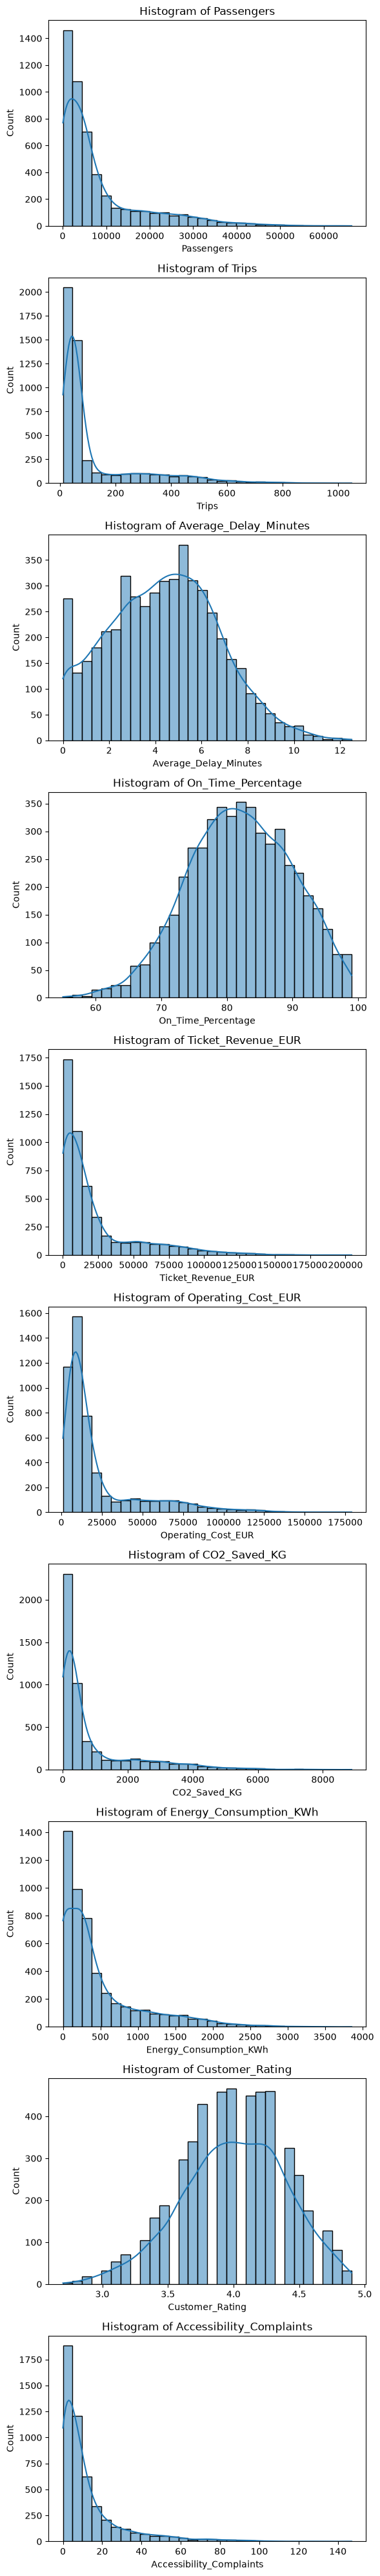

In [184]:
print("DATASET INFO\n")
display(df.info())
print("DATASET SHAPE\n")
display(df.shape)
print("SUMMARY STATISTICS\n")
display(df.describe())
print("MISSING DATA CHECK\n")
display(df.isna().sum())
print("DUPLICATE DATA CHECK")
display(df.duplicated().sum())

print("DATA DISTRIBUTION ON NUMERICAL COLUMNS FOR OUTLIER CHECK")
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.to_list()
numerical_columns.pop(0) # to exclude the date column

fig, axes = plt.subplots(len(numerical_columns), 1, figsize=(6, 4 * len(numerical_columns)))
for i, column in enumerate(numerical_columns):
    sns.histplot(df[column], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f"Histogram of {column}")

plt.tight_layout()
plt.show()

CHECKING FOR ACTUAL EXISTENCE OF OUTLIERS USING 1.5IQR GIVEN DATA DISTRIBUTION
----- Passengers -----
Q1: 1411.75, Q3: 10077.5, IQR: 8665.75
Lower Bound: -11586.88, Upper Bound: 23076.12
Number of Outliers: 525 Percentage of Outliers: 10.50%

----- Trips -----
Q1: 36.0, Q3: 106.0, IQR: 70.0
Lower Bound: -69.0, Upper Bound: 211.0
Number of Outliers: 955 Percentage of Outliers: 19.10%

----- Average_Delay_Minutes -----
Q1: 2.6, Q3: 6.0, IQR: 3.4
Lower Bound: -2.5, Upper Bound: 11.1
Number of Outliers: 11 Percentage of Outliers: 0.22%

----- On_Time_Percentage -----
Q1: 76.5, Q3: 87.9, IQR: 11.4
Lower Bound: 59.4, Upper Bound: 105.0
Number of Outliers: 10 Percentage of Outliers: 0.20%

----- Ticket_Revenue_EUR -----
Q1: 3280.33, Q3: 26329.65, IQR: 23049.32
Lower Bound: -31293.65, Upper Bound: 60903.64
Number of Outliers: 591 Percentage of Outliers: 11.82%

----- Operating_Cost_EUR -----
Q1: 7189.86, Q3: 22732.98, IQR: 15543.11
Lower Bound: -16124.81, Upper Bound: 46047.65
Number of Outlie

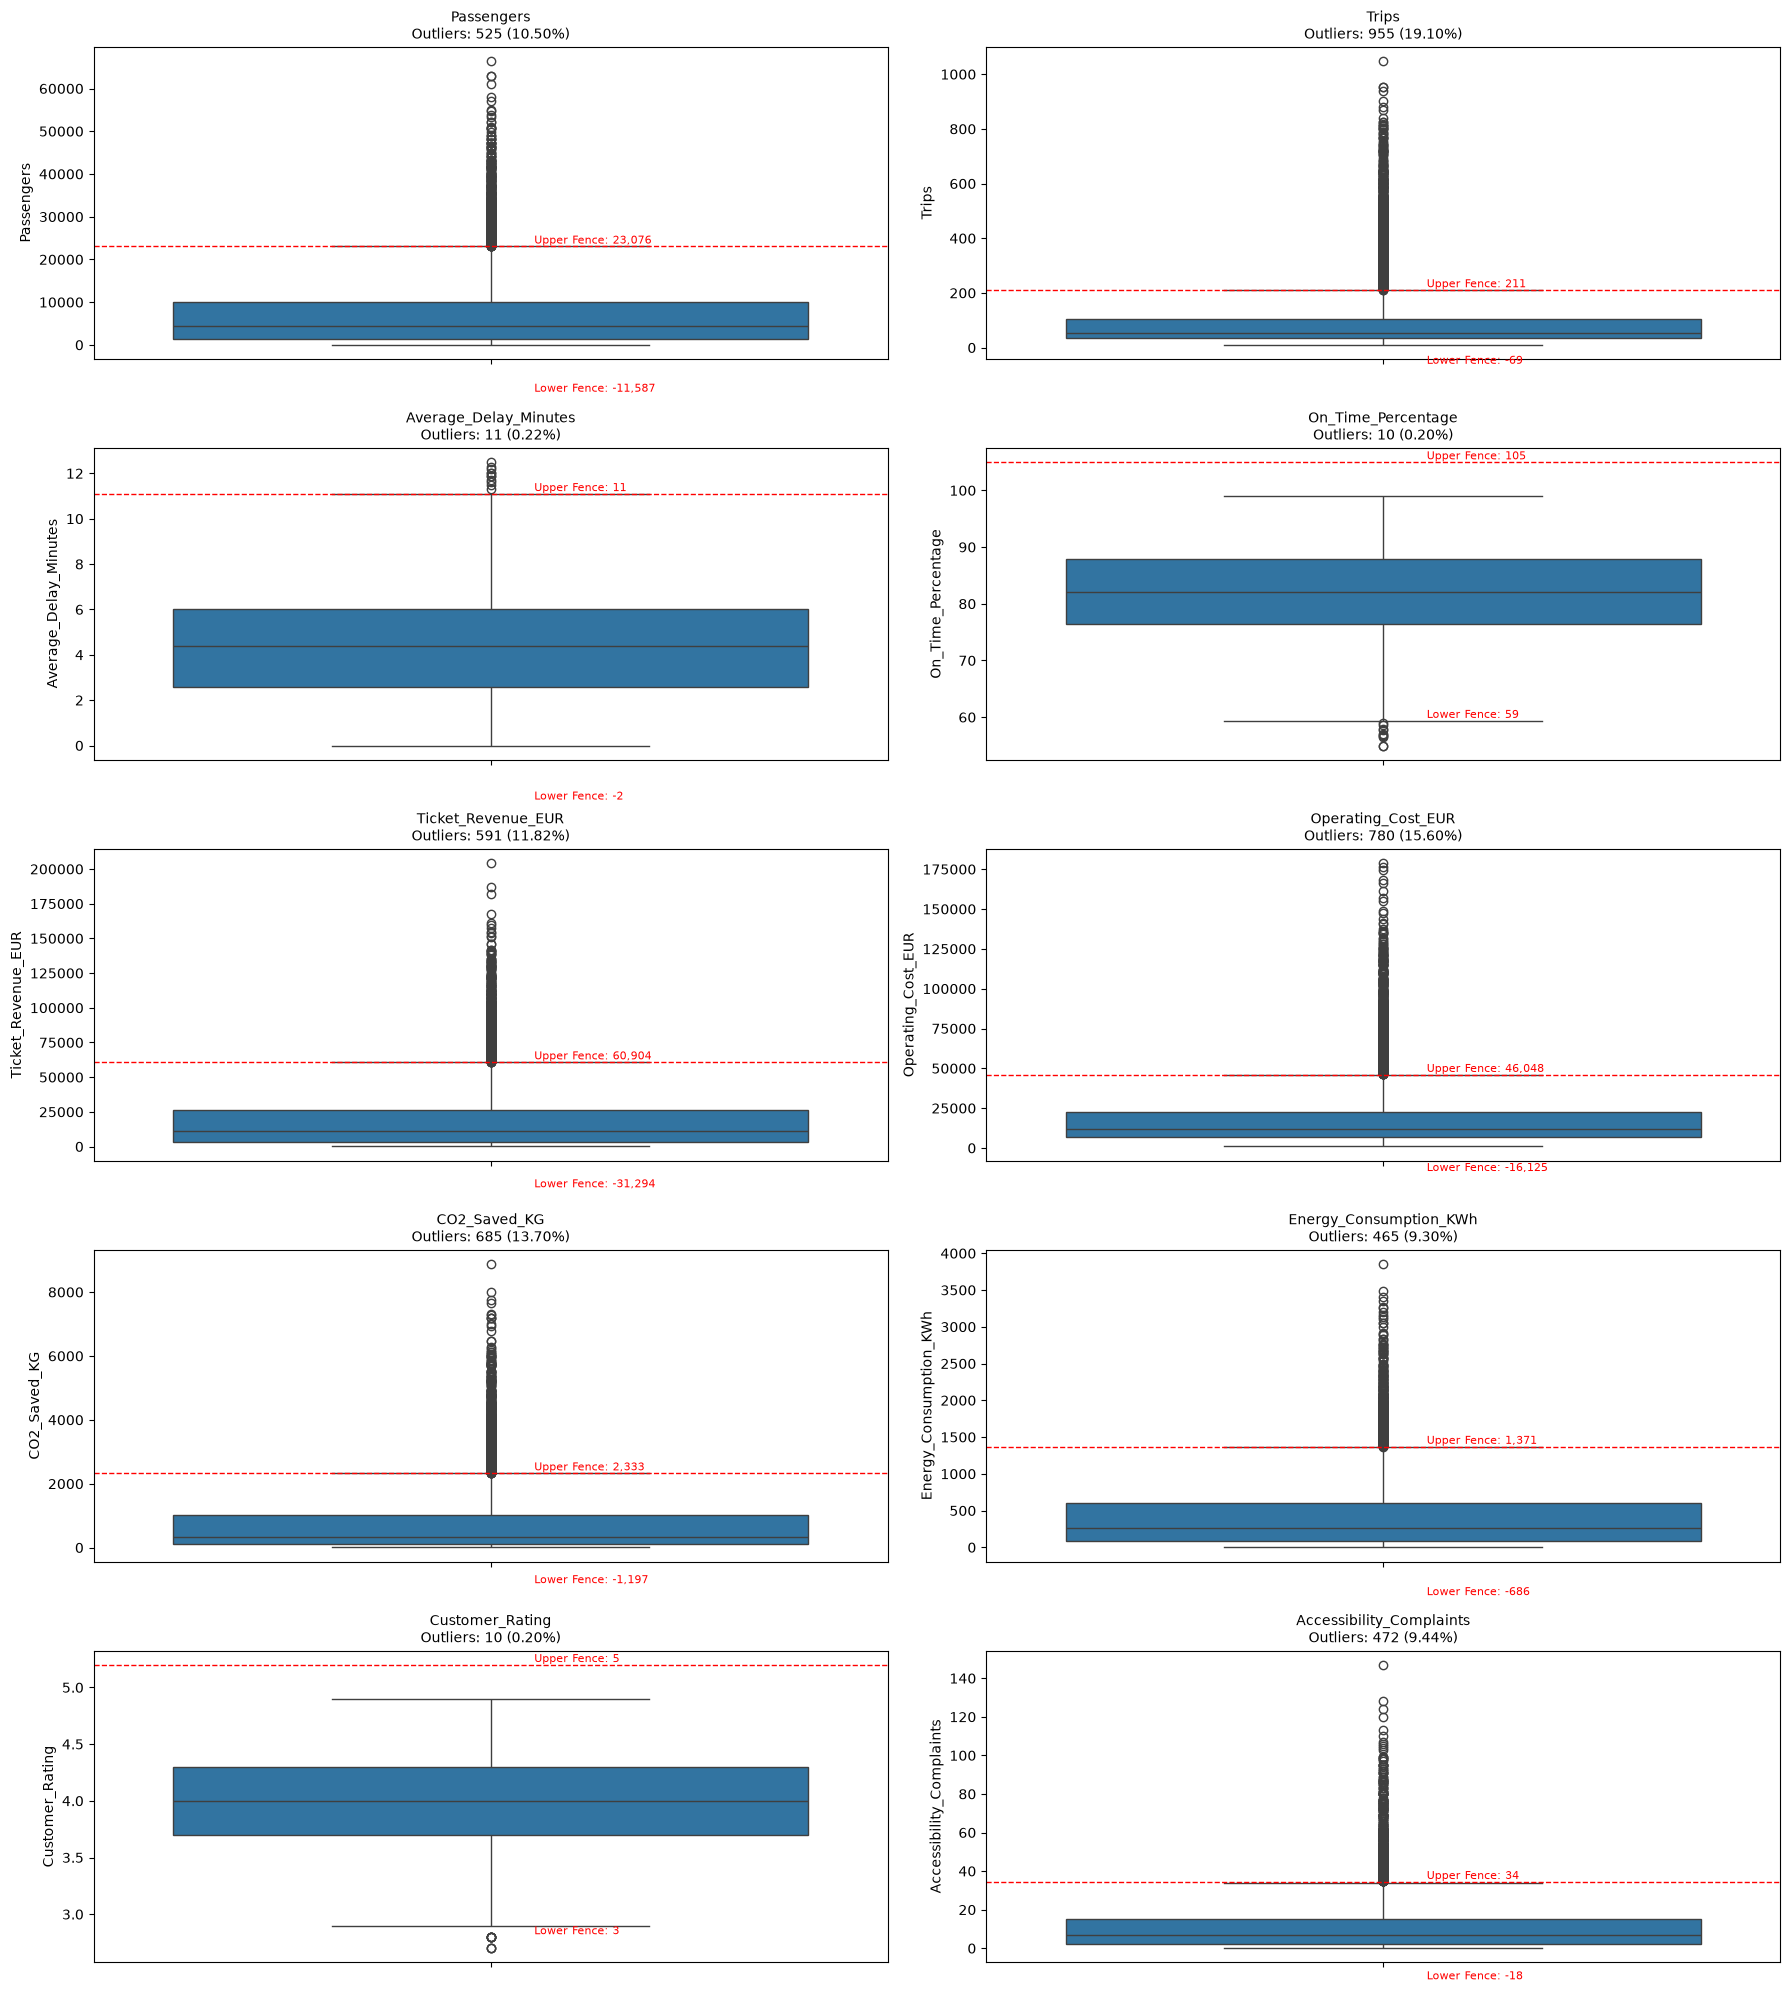

In [185]:
print("CHECKING FOR ACTUAL EXISTENCE OF OUTLIERS USING 1.5IQR GIVEN DATA DISTRIBUTION")
def iqr_outliers(series: pd.Series):
  """
    Calculates outliers for a given variable
    param series: the variable for which the outlier is to be calculated
  """
  q1 = series.quantile(0.25)
  q3 = series.quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - (1.5 * iqr)
  upper_bound = q3 + (1.5 * iqr)
  outliers = series[(series < lower_bound) | (series > upper_bound)]
  return q1, q3, iqr, lower_bound, upper_bound, outliers

for column in numerical_columns:
  q1, q3, iqr, lower_bound, upper_bound, outliers = iqr_outliers(df[column])
  print(f'----- {column} -----')
  print(f'Q1: {round(q1, 2)}, Q3: {round(q3, 2)}, IQR: {round(iqr, 2)}')
  print(f'Lower Bound: {round(lower_bound, 2)}, Upper Bound: {round(upper_bound, 2)}')
  print(f'Number of Outliers: {len(outliers)} Percentage of Outliers: {len(outliers)/len(df) * 100:.2f}%')
  print()

# representation with boxplot
fig, axes = plt.subplots(5, 2, figsize=(18, 20))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr
    n_out = ((df[column] < q1 - 1.5*iqr) | (df[column] > upper)).sum()

    sns.boxplot(y=df[column], ax=axes[i])
    axes[i].set_title(f'{column}\nOutliers: {n_out} ({n_out/len(df)*100:.2f}%)', fontsize=10)
    axes[i].axhline(upper, color='red', linestyle='--', linewidth=1)
    axes[i].text(0.05, upper, f' Upper Fence: {upper:,.0f}', color='red', fontsize=8, va='bottom')
    axes[i].text(0.05, lower, f' Lower Fence: {lower:,.0f}', color='red', fontsize=8, va='bottom')


for j in range(len(numerical_columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()

plt.show()

#### Issues Found
After inspecting the dataset, the following issues were found:
1. Missing Data - None
2. Incorrect Data (Outliers) - present but given the % and the impact it will have on the analysis, they will be retained.
3. Duplicate Data - None
4. Wrongly formatted Data - The date column is represented as Excel serial numbers (Excel's default setting of storing a date as a count of days) of type integer and has to be converted to the appropriate format

#### 2 - Cleaning

In [186]:
# converting the date column to the appropriate type and format
df['Date'] = pd.to_datetime(df['Date'], unit='D', origin='1899-12-30')
df

,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,2025-03-31,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,2025-03-01,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,2025-08-13,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,2024-07-31,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,2024-10-13,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,EM-04996,2024-12-22,Berlin,Germany,Bus,Central Route,Rain,No,3262,46,6.8,76.4,8323.79,8894.14,245.9,233.5,3.6,3
4996,EM-04997,2024-10-14,Barcelona,Spain,Park and Ride,Airport Connector,Windy,No,5017,36,6.7,74.7,15224.87,12196.03,259.6,186.0,3.5,13
4997,EM-04998,2025-07-30,Hamburg,Germany,Bus,Suburban Feeder,Cloudy,No,3302,44,7.3,75.7,7219.76,7331.86,262.3,286.2,3.7,5
4998,EM-04999,2024-11-20,Vienna,Austria,Tram,Tourist Zone,Cloudy,No,8564,41,6.1,73.2,20629.67,19786.98,889.0,510.7,3.5,6


## Step 2: Analysis
In order to effectively perform the analysis, more modifications beyond the Date variable data type conversion performed above will be carried out.

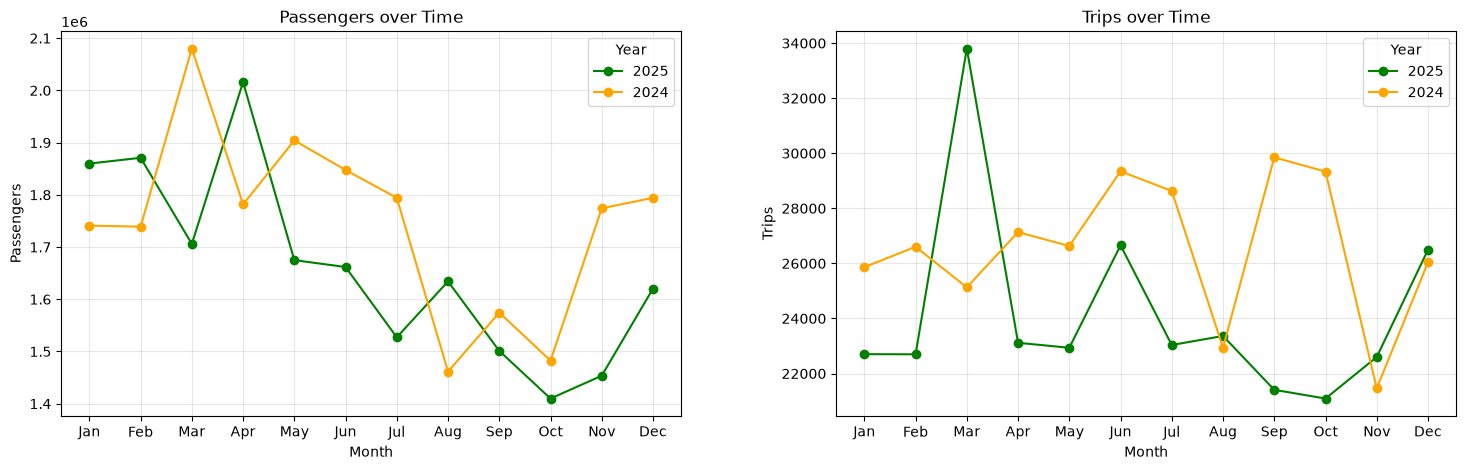

In [187]:
# time-series visualization to show mobility trends over time
# passengers  and trips over time

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['MonthNum'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)
df['DayOfWeek'] = df['Date'].dt.day_name()

total_monthly_passengers = df.groupby(['Year', 'MonthNum'])['Passengers'].sum()
total_monthly_trips = df.groupby(['Year', 'MonthNum'])['Trips'].sum()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
colors = {2024: 'orange', 2025: 'green'}
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

for year in df['Year'].unique():
    axes[0].plot(total_monthly_passengers[year].index, total_monthly_passengers[year], marker='o', label=str(year), color=colors[year])
    axes[1].plot(total_monthly_trips[year].index, total_monthly_trips[year], marker='o', label=str(year), color=colors[year])

axes[0].set_title('Passengers over Time')
axes[0].set_ylabel('Passengers')
axes[1].set_title('Trips over Time')
axes[1].set_ylabel('Trips')

for ax in axes:
    ax.set_xlabel('Month')
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(months)
    ax.legend(title='Year')
    ax.grid(alpha=0.3)

plt.subplots_adjust(wspace=0.25)
plt.show()


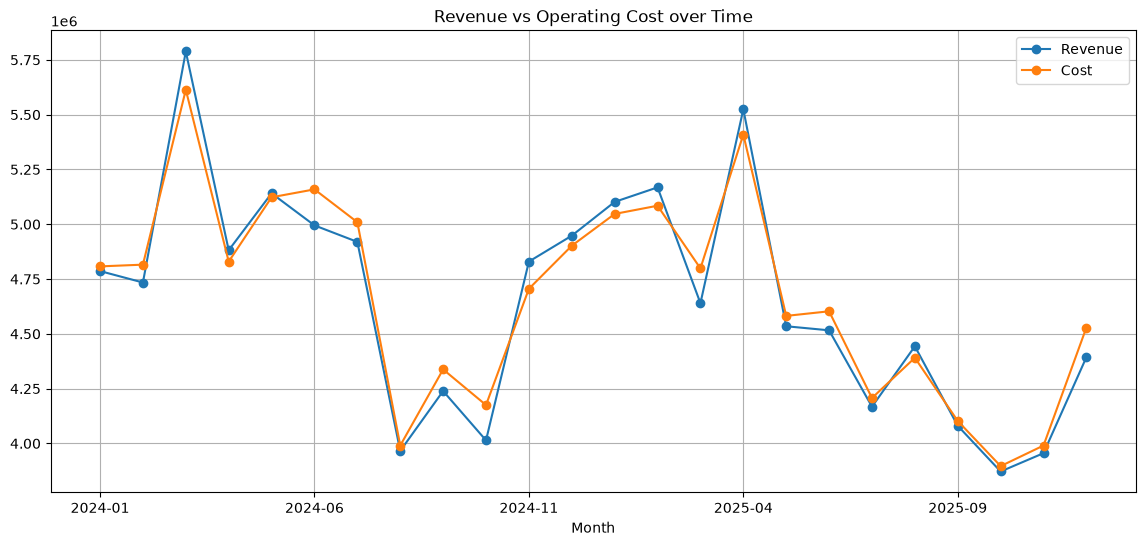

In [206]:
# continuation - ticket revenue vs operating cost over time (using method chaining)
(
    df.groupby('Month').agg(
        Revenue=('Ticket_Revenue_EUR', 'sum'),
        Cost=('Operating_Cost_EUR', 'sum')
    ).reset_index().sort_values('Month')
    .plot(x='Month', y=['Revenue', 'Cost'], kind='line', marker='o', figsize=(14,6), title='Revenue vs Operating Cost over Time', grid=True,)
)
plt.show()

In [188]:
df.dtypes

Record_ID                              str
Date                        datetime64[us]
City                                   str
Country                                str
Transport_Mode                         str
Route_Type                             str
Weather                                str
Event_Day                              str
Passengers                           int64
Trips                                int64
Average_Delay_Minutes              float64
On_Time_Percentage                 float64
Ticket_Revenue_EUR                 float64
Operating_Cost_EUR                 float64
CO2_Saved_KG                       float64
Energy_Consumption_KWh             float64
Customer_Rating                    float64
Accessibility_Complaints             int64
Year                                 int32
Month                                  str
MonthNum                             int32
Quarter                                str
DayOfWeek                              str
dtype: obje